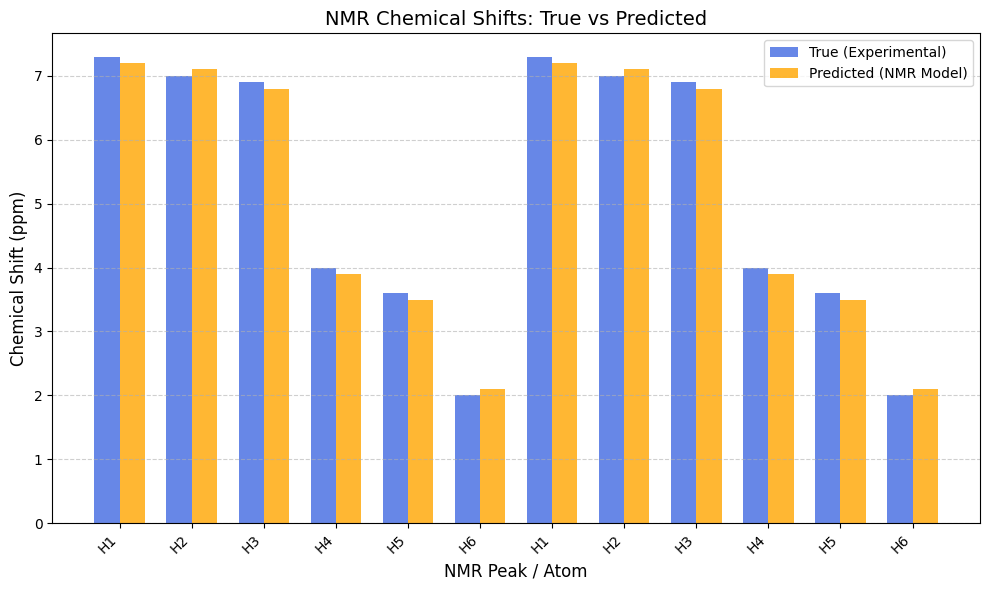

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 真实值与预测值
true_shifts = [7.3, 7.0, 6.9, 4.0, 3.6, 2.0]+[7.3, 7.0, 6.9, 4.0, 3.6, 2.0]
predicted_shifts = [7.2, 7.1, 6.8, 3.9, 3.5, 2.1] + [7.2, 7.1, 6.8, 3.9, 3.5, 2.1]
atom_labels = ["H1", "H2", "H3", "H4", "H5", "H6"] + ["H1", "H2", "H3", "H4", "H5", "H6"]

x = np.arange(len(true_shifts))  # 标签位置
width = 0.35  # 柱子宽度

fig, ax = plt.subplots(figsize=(10, 6))

# 绘制真实值柱子
bars1 = ax.bar(x - width/2, true_shifts, width, label='True (Experimental)', color='royalblue', alpha=0.8)

# 绘制预测值柱子
bars2 = ax.bar(x + width/2, predicted_shifts, width, label='Predicted (NMR Model)', color='orange', alpha=0.8)

# 设置坐标轴
ax.set_xlabel('NMR Peak / Atom', fontsize=12)
ax.set_ylabel('Chemical Shift (ppm)', fontsize=12)
ax.set_title('NMR Chemical Shifts: True vs Predicted', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(atom_labels, rotation=45, ha='right')
ax.legend()

# 添加网格
ax.grid(axis='y', linestyle='--', alpha=0.6)

# 自动调整布局
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import numpy as np
import os 
import json

In [6]:
df0 = pd.read_csv("../data/test_core_mol_nmr.csv", index_col=0)
df0.head()

,SMILES,NMR1,NMR,ori_result
0,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(NC4...,"175.4, 164.8, 153.5, 152.1, 151.8, 141.7, 134....","175.4, 164.8, 152.66 (d, JC-F = 254.7 Hz) 152....","{""data"": {""molfile"": ""\nActelion Java MolfileC..."
1,O=C1C(C(O)=O)=CN(C2CC2)C3=C4C(C(C=CC=C5)=C5N4)...,"176.8, 165.9, 156.6, 155.0, 148.0, 140.1, 130....","176.8, 165.9, 155.80 (d, JC-F = 248.4 Hz), 148...","{""data"": {""molfile"": ""\nActelion Java MolfileC..."
2,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(C4=...,"175.4, 164.6, 156.2, 154.9, 153.0, 141.5, 130....","175.4, 164.6, 155.6 (d, JC-F = 248.2 Hz), 153....","{""data"": {""molfile"": ""\nActelion Java MolfileC..."
3,O=C1C(C(O)=O)=CN(C2CC2)C3=C(N)C(C4=CC=CS4)=C(F...,"176.7, 176.7, 165.6, 158.8, 157.2, 151.1, 141....","176.7, 176.7, 165.6, 158.03 (d, JC-F = 243.8 H...","{""data"": {""molfile"": ""\nActelion Java MolfileC..."
4,O=C1C(C(O)=O)=CN(C2CC2)C3=C(F)C(N4CCN(C)CC4)=C...,"179.2, 165.4, 150.0, 141.2, 140.1, 138.6, 138....","179.2, 165.4, 150.0, 140.7 (d, JC-F = 234.0 Hz...","{""data"": {""molfile"": ""\nActelion Java MolfileC..."


In [58]:
df0.loc[0, "SMILES"]

'O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(NC4=CC=CC=C4)=C(F)C=C31'

In [80]:
index = 0
result_str = df0.loc[index, "ori_result"]
result = json.loads(result_str)
predicted_shifts = []
for i in range(len(result["data"]["joinedSignals"])):
    predicted_shifts.append(result["data"]["joinedSignals"][i]["delta"])
predicted_shifts = list(set(predicted_shifts))
predicted_shifts.sort()
true_shifts = [eval(i) for i in df0.loc[index, "NMR1"].rstrip(".").split(", ")]
true_shifts = list(set(true_shifts))
true_shifts.sort()

In [81]:
predicted_shifts_2 = [
    176.55,
    109.53,
    165.12,
    150.05,
    36.89,
    9.08,
    8.94,
    133.88,
    131.06,
    134.95,
    141.09,
    119.47,
    129.49,
    122.91,
    129.38,
    118.23,
    150.34,
    114.76,
    121.54
]
predicted_shifts_2 = list(set(predicted_shifts_2))
predicted_shifts_2.sort()

In [82]:
true_shifts, predicted_shifts

([10.1,
  39.7,
  108.9,
  114.3,
  114.4,
  118.8,
  120.9,
  122.9,
  128.8,
  132.4,
  132.5,
  133.5,
  134.8,
  141.7,
  151.8,
  152.1,
  153.5,
  164.8,
  175.4],
 [6.8,
  37.35,
  107.6,
  109.35,
  120.7,
  123.58,
  123.95,
  129.25,
  138.1,
  141.8,
  142,
  157.2,
  166.15,
  174.4])

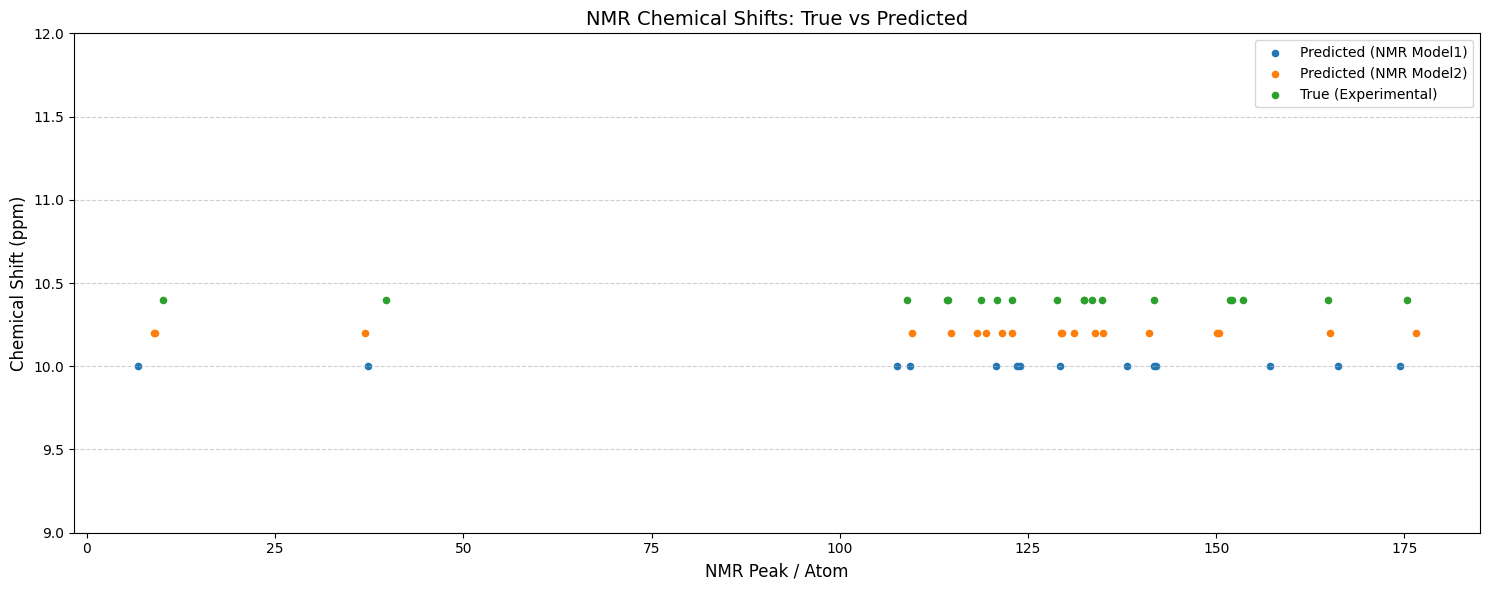

In [83]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.scatter(predicted_shifts, [10 for i in predicted_shifts], s=20, label='Predicted (NMR Model1)')
plt.scatter(predicted_shifts_2, [10.2 for i in predicted_shifts_2], s=20, label='Predicted (NMR Model2)')
plt.scatter(true_shifts, [10.4 for i in true_shifts], s=20, label='True (Experimental)')
# 设置坐标轴

ax.set_ylim(9, 12)
ax.set_xlabel('NMR Peak / Atom', fontsize=12)
ax.set_ylabel('Chemical Shift (ppm)', fontsize=12)
ax.set_title('NMR Chemical Shifts: True vs Predicted', fontsize=14)
# ax.set_xticks([i * 0.1 for i in range(-100, 2300)])

ax.legend()

# 添加网格
ax.grid(axis='y', linestyle='--', alpha=0.6)

# 自动调整布局
plt.tight_layout()
plt.show()

In [84]:
len(true_shifts), len(predicted_shifts_2), len(predicted_shifts)

(19, 19, 14)